# CIFAR10 additive normalizing-flow geometry experiment

Adapted from `mnist_additive_nflow.ipynb`. Run in the same project environment with the original `src` package, PyTorch, torchvision, nflows, NumPy, Pillow, matplotlib, and tqdm. These notebooks have not been executed against your project implementation.

## Preserved experiments
- Same parity-convolution/tanh flow, standard-normal base, L=128, K=5, order=6, six flows, Adam learning rate 0.001, and 100 epochs.
- Seed 31 and 80/20 split; no augmentation or dequantization (matching the original experiment).
- Sampling; pullback geodesics and barycentre; rank-20 tangent-space PGA; isometrized geodesics and PGA with five intervals; Euclidean geodesics and PCA; relative RMSE and scatter comparisons.
- The source's shared pullback barycentre is deliberately retained as the base point for all three low-rank solvers, including Euclidean PCA. This is not recentered Euclidean PCA.

## Dataset-specific changes and execution
- Input is 3 x 32 x 32; normalization is fixed channelwise mean/std 0.5, i.e. pixel values map to [-1, 1]. Inverse normalization and clipping apply only to plots, never calculations.
- Training defaults to enabled. `resume_training=True` resumes a local last checkpoint; the best training-NLL checkpoint is loaded for analysis. Checkpoints now store correctly updated best loss and sample-weighted epoch NLL.
- All results go to a dataset-specific directory. Existing source outputs are removed.
- CIFAR-10 downloads through torchvision. The official training partition is split 80/20 as in the source; the official test set is not used. Training and analysis batch sizes are both 128.

The original custom image classes must support three channels. Only the notebook was supplied; their implementation and numerical behavior cannot be verified here.


In [1]:
import os
import glob
import numpy as np
import torch
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import matplotlib.pyplot as plt
from nflows import flows, transforms, distributions
from nflows.transforms.normalization import ActNorm
from tqdm import tqdm

from src.diffeomorphisms.image.nflow import NFlowImageDiffeomorphism
from src.dimension_reduction.principal_geodesic_analysis.image.l2_tangent_space_pca import l2TangentSpacePCAImageSolver
from src.manifolds.euclidean.image.pullback.standard import StandardPullbackImageEuclidean
from src.manifolds.euclidean.image.standard import StandardImageEuclidean
from src.manifolds.isometrized_euclidean.image import l2IsometrizedImageEuclidean
from src.transforms.multi_layer_parity_conv2d.tanh import MultiLayerTanhParityConv2DTransform
from src.transforms.parity_conv import ParityConv2DTransform

device = "cuda" if torch.cuda.is_available() else "cpu"

# Set random seed for reproducibility
seed = 31
torch.manual_seed(seed)
np.random.seed(seed)

# Experiment settings
size = 32
C = 3
results_folder = os.path.join("results",f"cifar10_{size}x{size}","additive-tanh-isotropic-nflow-pullback")
train_model = True
resume_training = True

plt.rcParams['font.size'] = 20  # Change this value to your desired font size
os.makedirs(results_folder, exist_ok=True)


### Learning Geometry ###

Files already downloaded and verified


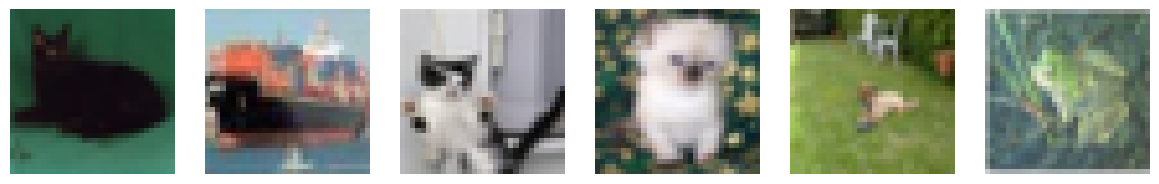

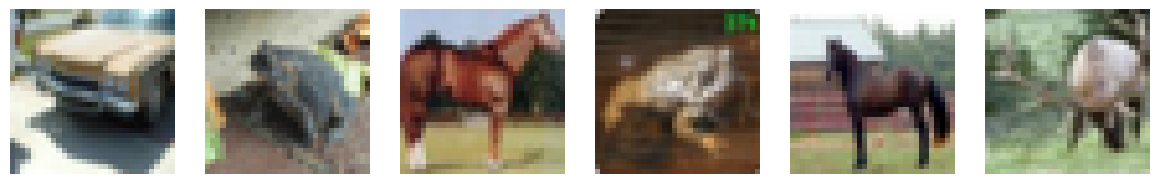

In [2]:
H, W = size, size
# Fixed affine normalization: same convention for both RGB datasets.
image_mean = (0.5, 0.5, 0.5)
image_std = (0.5, 0.5, 0.5)
transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(image_mean, image_std),
])
full_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform)
batch_size = 128
analysis_batch_size = 128
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
if train_size == 0 or val_size < analysis_batch_size:
    raise ValueError('Dataset too small for the configured split and analysis sample.')
data_train, data_val = random_split(full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(seed))
train_loader = DataLoader(data_train, batch_size=batch_size, shuffle=False, num_workers=0)
val_loader = DataLoader(data_val, batch_size=analysis_batch_size, shuffle=False, num_workers=0)
train_images, _ = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))

# Display only: all calculations use unclipped, normalized RGB tensors.
def display_image(image):
    image = torch.as_tensor(image).detach().cpu().reshape(C, H, W)
    mean = torch.tensor(image_mean).view(C, 1, 1)
    std = torch.tensor(image_std).view(C, 1, 1)
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

for images in (train_images, val_images):
    fig, axes = plt.subplots(1, 6, figsize=(12, 3))
    for i, ax in enumerate(axes):
        ax.imshow(display_image(images[i]))
        ax.axis('off')
    plt.tight_layout()
    plt.show()


In [3]:
# Define the normalizing flow model
def create_flow_model(in_channels, height, width, kernel_size, latent_channels, order, n_flows, unit_det=False, parity_equivariance=False, actnorm=True):
    base_dist = distributions.StandardNormal(shape=[in_channels, height, width])
    transforms_list = []
    for i in range(n_flows):
        if actnorm:
            transforms_list.append(ActNorm(features=in_channels))
        transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=i, unit_det=unit_det, parity_equivariance=parity_equivariance))
        transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=i+1, unit_det=unit_det, parity_equivariance=parity_equivariance))
        transforms_list.append(MultiLayerTanhParityConv2DTransform(in_channels, height, width, kernel_size, latent_channels, order=order, parity=i))
    if actnorm:
            transforms_list.append(ActNorm(features=in_channels))
    transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=n_flows, unit_det=unit_det, parity_equivariance=parity_equivariance))
    transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=n_flows+1, unit_det=unit_det, parity_equivariance=parity_equivariance))
    flow_transforms = transforms.CompositeTransform(transforms_list)
    return flows.Flow(transform=flow_transforms, distribution=base_dist)

In [4]:
# Initialize the model
L = 128
K = 5
order = 6
n_flows = 6
model = create_flow_model(C, H, W, K, L, order, n_flows).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [5]:
# Generate samples
@torch.no_grad()
def generate_samples(model, n_samples):
    samples = model.sample(n_samples).cpu()
    return samples

In [6]:
# Same likelihood objective and training-loss checkpoint selection as the source.
def train(phi, train_loader, optimizer, n_epochs, save_dir='results', start_epoch=0,
          best_loss=float('inf')):
    os.makedirs(save_dir, exist_ok=True)
    for epoch in range(start_epoch, n_epochs):
        phi.train()
        total_loss, count = 0.0, 0
        for x, _ in tqdm(train_loader, desc=f"Epoch {epoch+1}/{n_epochs}"):
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = -phi.nflow.log_prob(x).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss')
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x)
            count += len(x)
        avg_epoch_loss = total_loss / count
        improved = avg_epoch_loss < best_loss
        best_loss = min(best_loss, avg_epoch_loss)
        checkpoint = {
            'epoch': epoch, 'model_state_dict': phi.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': avg_epoch_loss, 'best_loss': best_loss,
            'torch_rng_state': torch.get_rng_state(),
        }
        if torch.cuda.is_available():
            checkpoint['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
        torch.save(checkpoint, os.path.join(save_dir, 'last_model.pth'))
        if (epoch + 1) % 25 == 0:
            torch.save(checkpoint, os.path.join(save_dir, f'epoch_{epoch+1}_model.pth'))
        if improved:
            torch.save(checkpoint, os.path.join(save_dir, 'best_model.pth'))
        print(f"Epoch {epoch+1}: NLL/image={avg_epoch_loss:.4f}; best={best_loss:.4f}")


In [7]:
n_epochs = 100
phi = NFlowImageDiffeomorphism(C, H, W, model)
checkpoint_dir = os.path.join(results_folder,
    f"checkpoints_latent_dim={L}_kernel_size={K}_order={order}_n_flows={n_flows}")
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path = os.path.join(checkpoint_dir, 'best_model.pth')
if train_model:
    start_epoch, best_loss = 0, float('inf')
    last_path = os.path.join(checkpoint_dir, 'last_model.pth')
    if resume_training and os.path.isfile(last_path):
        checkpoint = torch.load(last_path, map_location=device, weights_only=True)
        phi.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_loss = checkpoint['best_loss']
        torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
        if torch.cuda.is_available() and 'cuda_rng_state_all' in checkpoint:
            torch.cuda.set_rng_state_all([s.cpu() for s in checkpoint['cuda_rng_state_all']])
    train(phi, train_loader, optimizer, n_epochs, checkpoint_dir, start_epoch, best_loss)
if not os.path.isfile(best_model_path):
    raise FileNotFoundError('No best checkpoint. Set train_model=True to train first.')
checkpoint = torch.load(best_model_path, map_location=device, weights_only=True)
phi.load_state_dict(checkpoint['model_state_dict'])
phi.eval()


Epoch 1/100: 100%|██████████| 313/313 [02:17<00:00,  2.27it/s]


Epoch 1: NLL/image=9418.7828; best=9418.7828


Epoch 2/100: 100%|██████████| 313/313 [02:15<00:00,  2.31it/s]


Epoch 2: NLL/image=3746.8243; best=3746.8243


Epoch 3/100: 100%|██████████| 313/313 [02:16<00:00,  2.30it/s]


...

Epoch 99/100: 100%|██████████| 313/313 [02:16<00:00,  2.29it/s]


Epoch 99: NLL/image=-282560.9857; best=-282560.9857


Epoch 100/100: 100%|██████████| 313/313 [02:15<00:00,  2.31it/s]


Epoch 100: NLL/image=-285836.8893; best=-285836.8893


NFlowImageDiffeomorphism(
  (nflow): Flow(
    (_transform): CompositeTransform(
      (_transforms): ModuleList(
        (0): ActNorm()
        (1-2): 2 x ParityConv2DTransform(
          (conv2d): Conv2d(3, 3, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
        )
        (3): MultiLayerTanhParityConv2DTransform(
          (cnn): Sequential(
            (0): MaskedConv2d(3, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
            (1): TanhActivation()
            (2): MaskedConv2d(128, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
            (3): TanhActivation()
            (4): MaskedConv2d(128, 3, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
          )
        )
        (4): ActNorm()
        (5-6): 2 x ParityConv2DTransform(
          (conv2d): Conv2d(3, 3, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
        )
        (7): MultiLayerTanhParityConv2DTransform(
          (cnn): Sequential(
            (0): MaskedConv

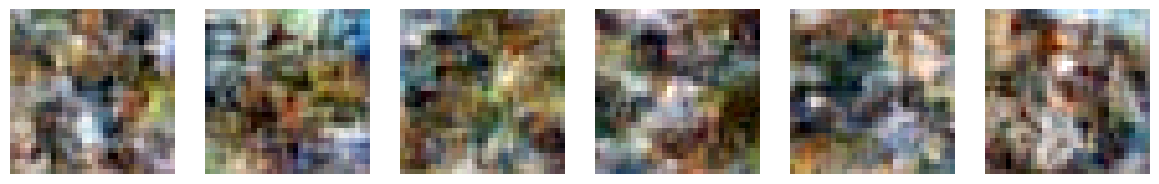

In [8]:
# Visualize generated samples
samples = generate_samples(phi.nflow, 100).reshape(-1, C, H, W)

# Plot the first 6 images
fig, axes = plt.subplots(1, 6, figsize=(12, 8))
axes = axes.flatten()

for i in range(6):
    axes[i].imshow(display_image(samples[i].squeeze()))
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [5]:
# special points
num_points = 10
num_geodesics = 5

x0 = val_images[0:2*num_geodesics:2].to(device)
x1 = val_images[1:2*num_geodesics+1:2].to(device)

### Naive Riemannian data analysis ###

In [10]:
# Construct pullback manifold
manifold = StandardPullbackImageEuclidean(phi)

In [11]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    geodesics[i] = manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

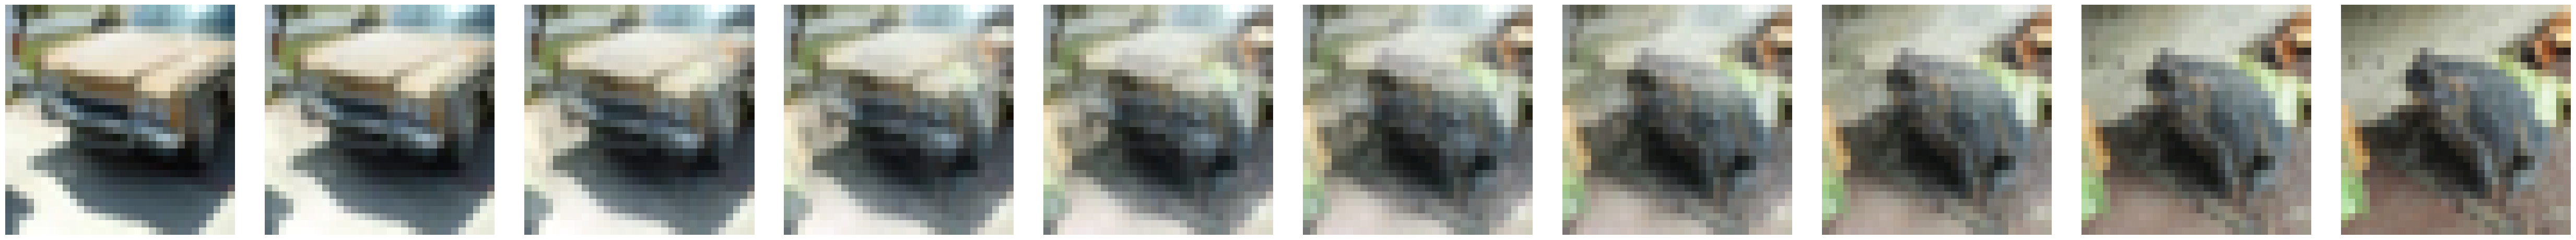

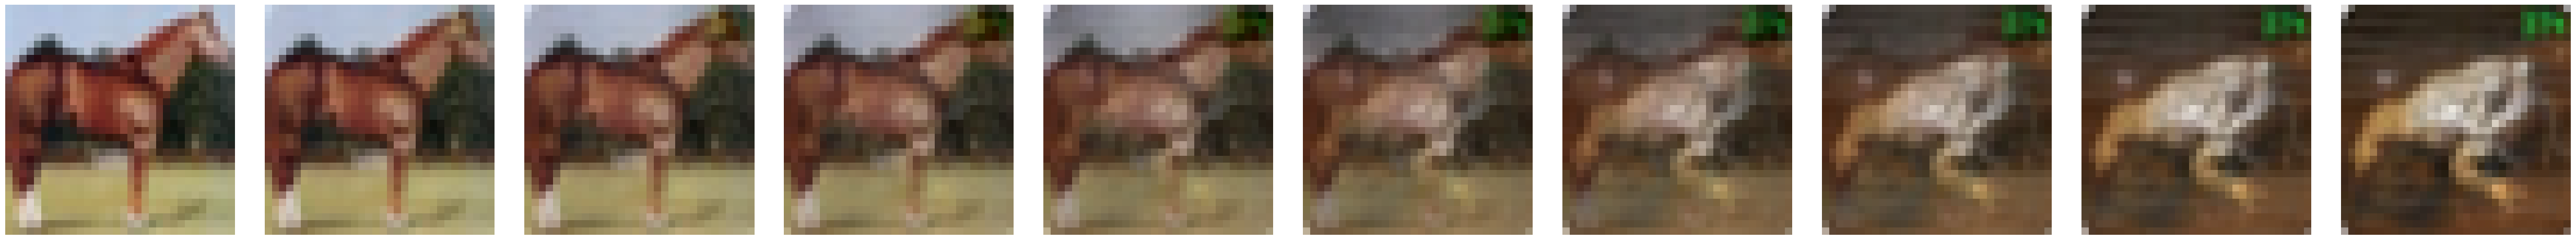

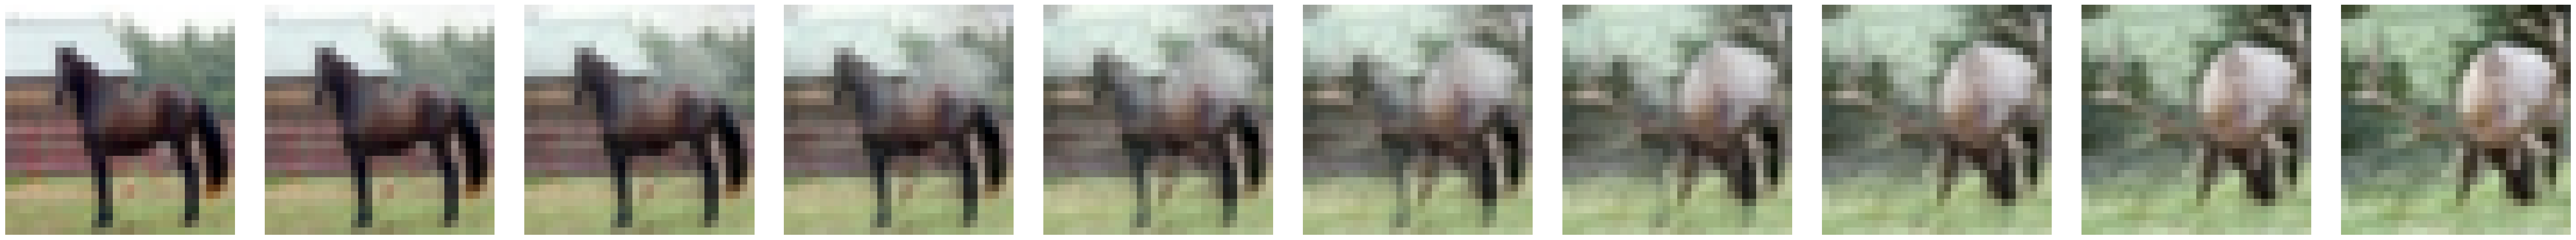

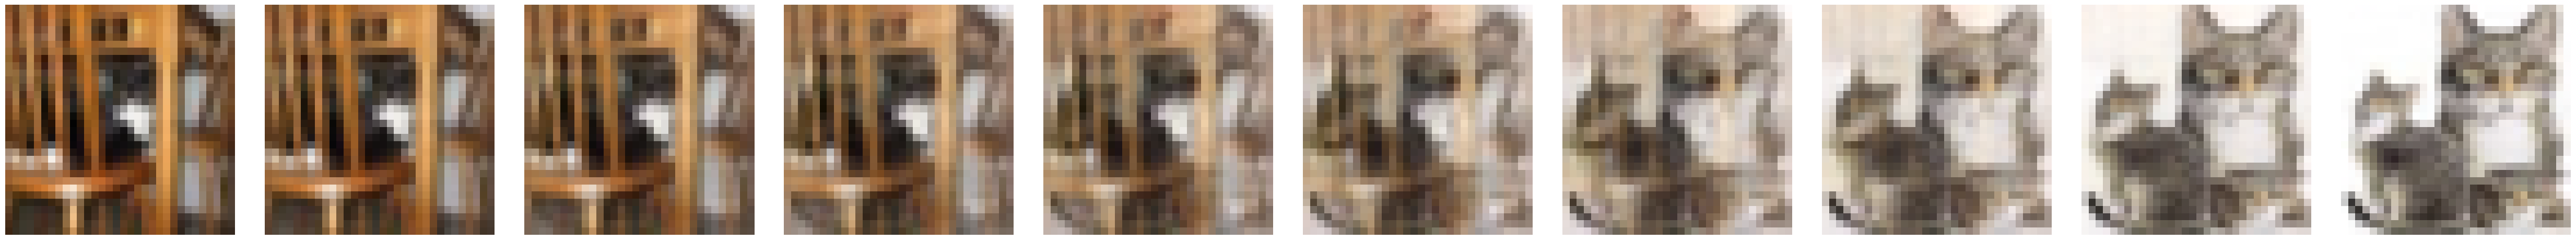

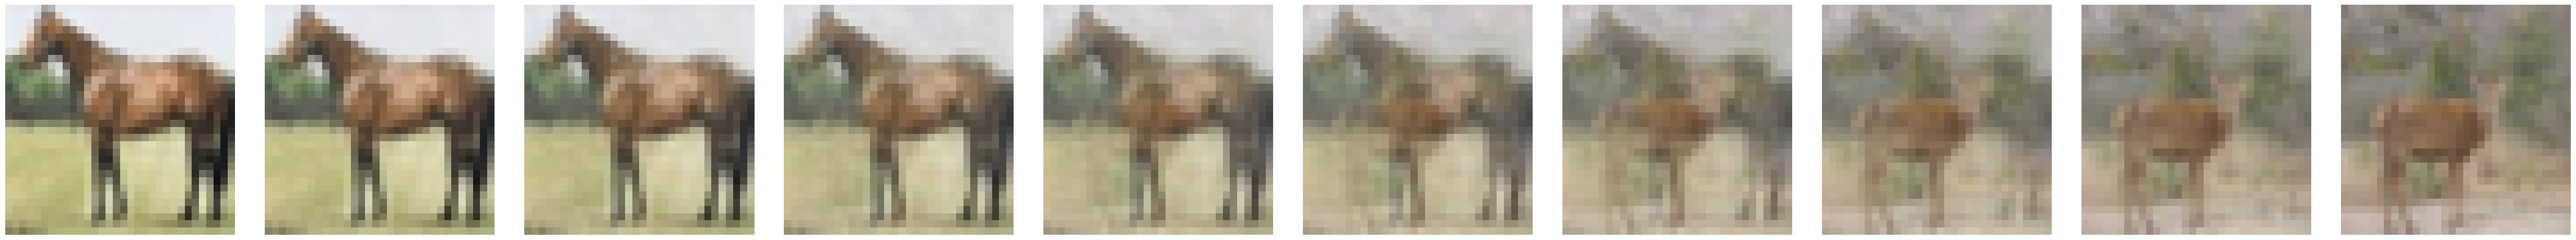

In [12]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1,num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"geodesic-{i}.eps"))
    plt.show()

In [13]:
# Compute barycentre
bary = manifold.barycentre(val_images.to(device)).detach().cpu()

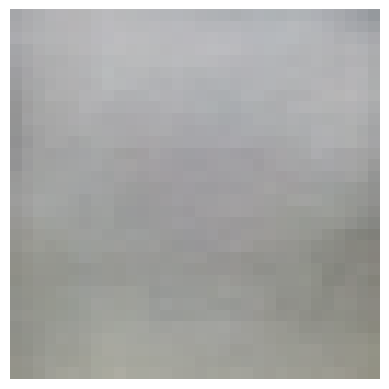

In [14]:
# Plot barycentres
plt.imshow(display_image(bary.squeeze()))
plt.axis('off')
plt.show()

In [15]:
# Construct curvature corrected l2-pga solver
l2_pga_solver = l2TangentSpacePCAImageSolver(val_images.to(device), manifold, bary.to(device))

OutOfMemoryError: CUDA out of memory. Tried to allocate 448.00 MiB. GPU 0 has a total capacity of 31.73 GiB of which 248.56 MiB is free. Including non-PyTorch memory, this process has 31.44 GiB memory in use. Of the allocated memory 30.93 GiB is allocated by PyTorch, and 132.85 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
# Compute low rank approximations
Xi_bary, exp_bary_Xi, _ = l2_pga_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"val-l2-pga.eps"))
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"l2-pga.eps"))
plt.show()

### Isometrized Riemannian data analysis ###

In [ ]:
# Construct isometrized pullback manifold
num_intervals = 5  # You can adjust this value as needed
iso_manifold = l2IsometrizedImageEuclidean(manifold, num_intervals=num_intervals)

In [ ]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

iso_geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    iso_geodesics[i] = iso_manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

In [ ]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(iso_geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"iso-geodesic-{i}-M{num_intervals}.eps"))
    plt.show()

In [ ]:
# Construct curvature corrected l2-pga solver
iso_l2_pga_solver = l2TangentSpacePCAImageSolver(val_images.to(device), iso_manifold, bary.to(device))

In [ ]:
# Compute low rank approximations
iso_Xi_bary, iso_exp_bary_Xi, _ = iso_l2_pga_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(iso_exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,f"iso-l2-pga-M{num_intervals}.eps"))
plt.show()

### l2 data analysis ###

In [3]:
# Construct manifold
l2_manifold = StandardImageEuclidean(C, H, W)

In [6]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

l2_geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    l2_geodesics[i] = l2_manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

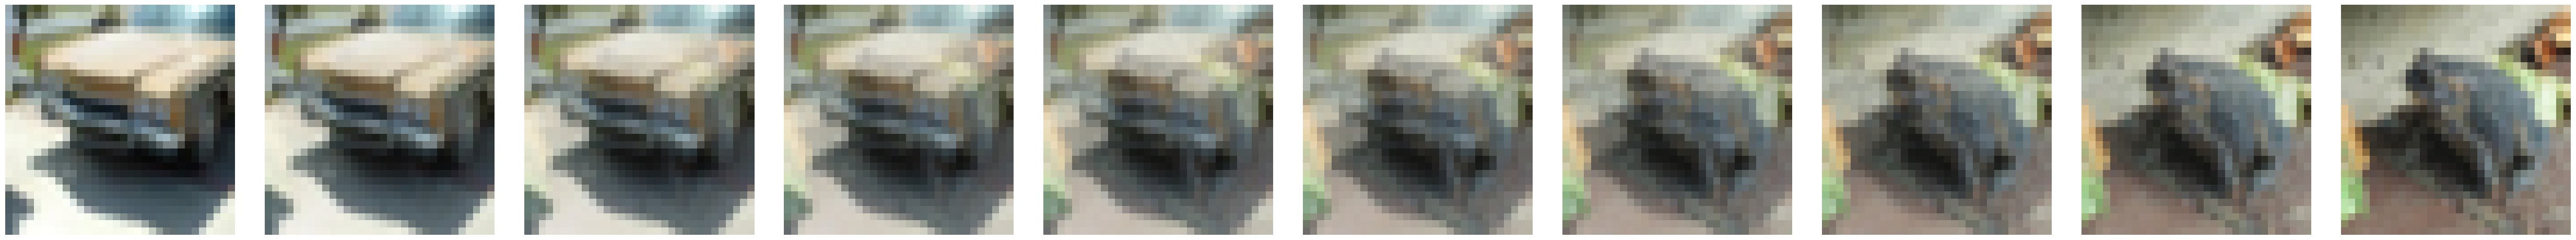

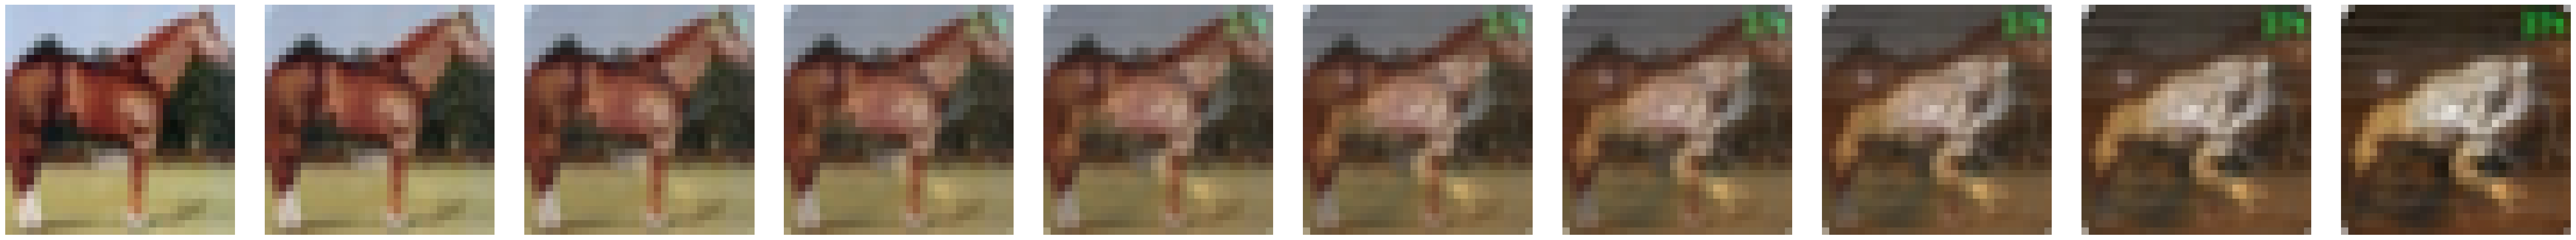

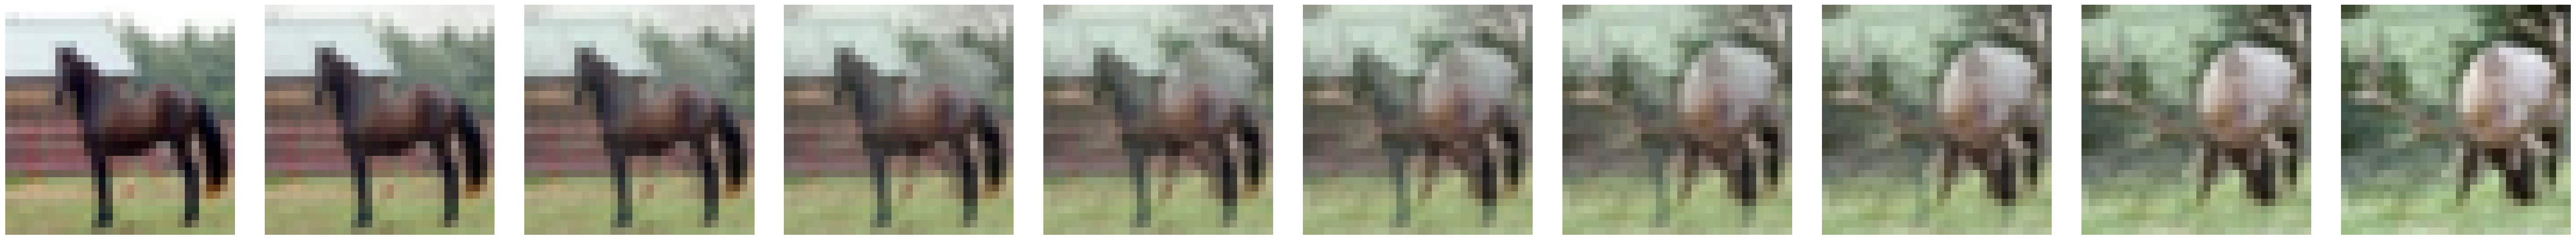

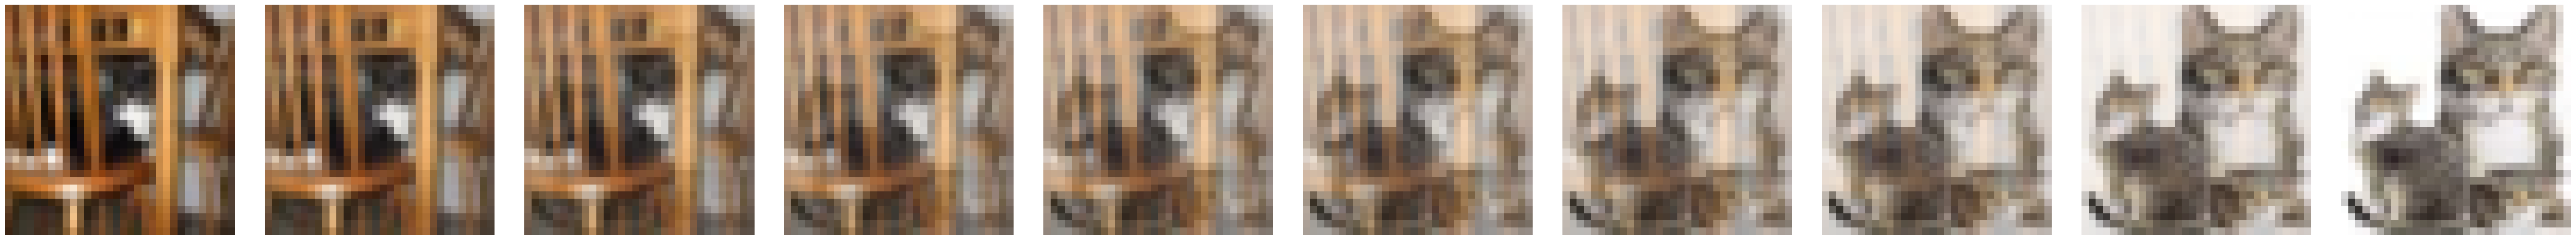

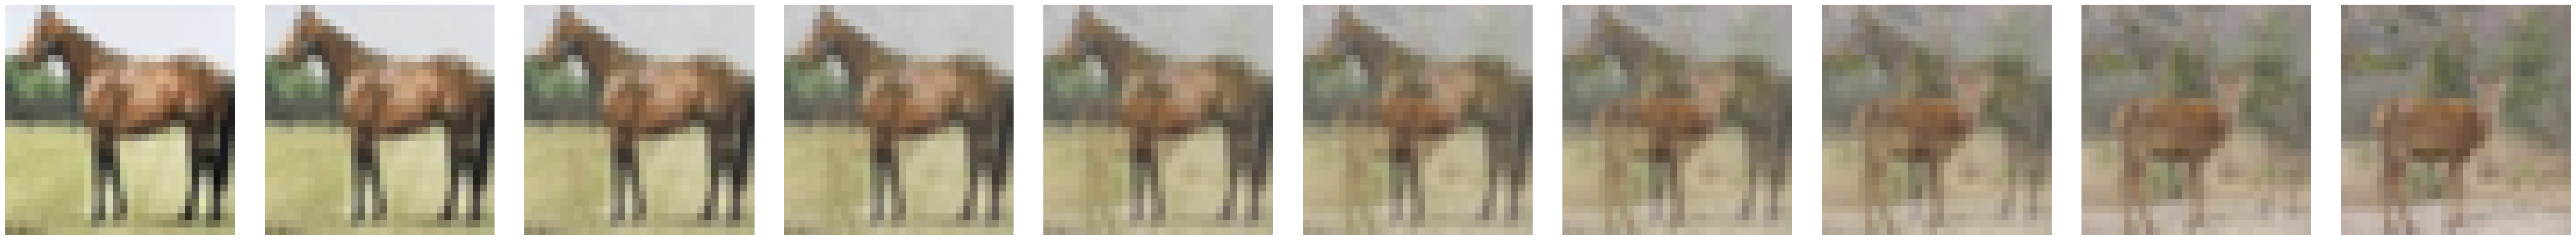

In [7]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(l2_geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"l2-geodesic-{i}.eps"))
    plt.show()

In [ ]:
# Construct curvature corrected l2-pga solver
l2_pca_solver = l2TangentSpacePCAImageSolver(val_images.to(device), l2_manifold, bary.to(device))

In [ ]:
# Compute low rank approximations
l2_Xi_bary, l2_exp_bary_Xi, _ = l2_pca_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(l2_exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"l2-pca.eps"))
plt.show()

### Comparing naive and isometrized ###

In [ ]:
# Compute geodesic relative rmse from the barycentre
squared_geo_errors = torch.zeros(len(val_images))
dists = ((val_images - bary)**2).sum([1,2,3])
for i, x_i in enumerate(val_images):
    geodesic_i = manifold.geodesic(bary.to(device)[None,None], x_i.to(device)[None,None], t).detach().cpu()[0,0,0]
    iso_geodesic_i = iso_manifold.geodesic(bary.to(device)[None,None], x_i.to(device)[None,None], t).detach().cpu()[0,0,0]
    squared_geo_errors[i] = ((geodesic_i - iso_geodesic_i)**2).mean(0).sum()

geo_rel_rmse = (squared_geo_errors.mean() / dists.mean()).sqrt()
print(geo_rel_rmse)

In [ ]:
# Make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(dists.sqrt(), squared_geo_errors.sqrt())
plt.xlim([0.,dists.sqrt().max()*1.1])
# Use automatic y limits for RGB data.
plt.xlabel('distance from barycentre')
plt.ylabel('geodesic error')
plt.savefig(os.path.join(results_folder,f"geo-error-M{num_intervals}.eps"))
plt.show()

In [ ]:
# Compute low rank relative rmse from the barycentre
squared_low_rank_errors = ((val_images - exp_bary_Xi.cpu())**2).sum([1,2,3])
low_rank_rel_rmse = (squared_low_rank_errors.mean() / dists.mean()).sqrt()

squared_low_rank_iso_errors = ((val_images - iso_exp_bary_Xi.cpu())**2).sum([1,2,3])
iso_low_rank_rel_rmse = (squared_low_rank_iso_errors.mean() / dists.mean()).sqrt()

squared_low_rank_l2_errors = ((val_images - l2_exp_bary_Xi.cpu())**2).sum([1,2,3])
l2_low_rank_rel_rmse = (squared_low_rank_l2_errors.mean() / dists.mean()).sqrt()

print(low_rank_rel_rmse)
print(iso_low_rank_rel_rmse)
print(l2_low_rank_rel_rmse)

In [ ]:
# Make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(dists.sqrt(), squared_low_rank_errors.sqrt() - squared_low_rank_iso_errors.sqrt())
plt.xlim([0.,dists.sqrt().max()*1.1])
# Use automatic y limits for RGB data.
plt.xlabel('distance from barycentre')
plt.ylabel('low-rank error')
plt.savefig(os.path.join(results_folder,f"low-rank-error-M{num_intervals}.eps"))
plt.show()